# Lab 4 - Face Image Classification
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective
Implement a real-world face classification model using the Labeled Faces in the Wild (LFW) dataset, reduce dimensionality with Principal Component Analysis (PCA / RandomizedPCA), tune an RBF-kernel Support Vector Classifier using GridSearchCV, and evaluate results using classification report and confusion matrix.

## Step 0 - Download / Load the Dataset

In [1]:
from sklearn.datasets import fetch_lfw_people

faces = fetch_lfw_people(min_faces_per_person=60)
print('Target names:', faces.target_names)
print('Number of target classes:', len(faces.target_names))
print('Images array shape:', faces.images.shape)

Target names: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Number of target classes: 8
Images array shape: (1348, 62, 47)


## Step 1 - Inspect Facial Images

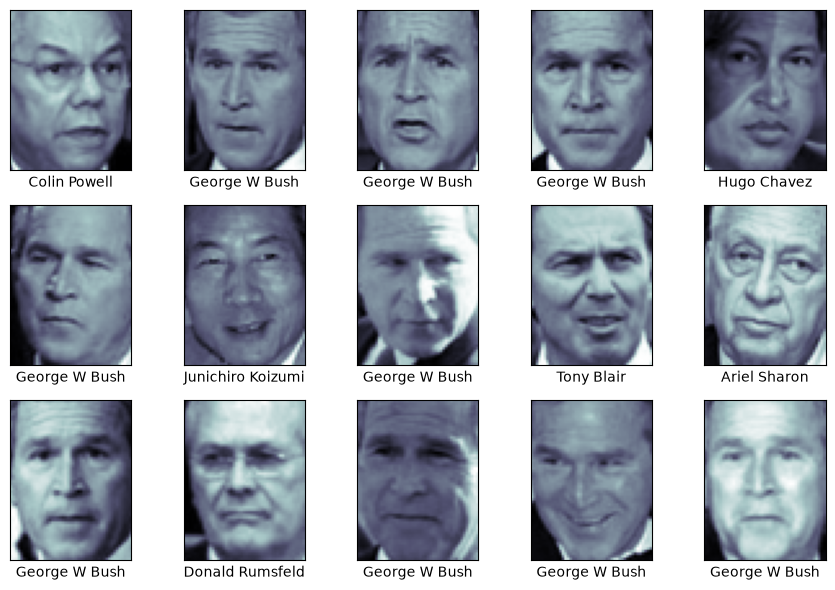

In [2]:
from matplotlib import pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(3, 5, figsize=(9, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.tight_layout()
plt.show()

## Step 2 - Data Preprocessing with PCA
We use Principal Component Analysis (PCA) to extract 150 principal components from the 2,914 original pixel features ($62 \times 47$), followed by an RBF SVM classifier assembled in a Scikit-Learn Pipeline.

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline executes PCA dimensionality reduction followed by SVC training
model = make_pipeline(pca, svc)

## Step 3 - Split Data into Training and Testing Sets

In [4]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)
print(f'Training samples: {Xtrain.shape[0]}')
print(f'Testing samples : {Xtest.shape[0]}')

Training samples: 1011
Testing samples : 337


## Step 4 - Model Creation + Hyperparameter Tuning with GridSearchCV
We use `GridSearchCV` to systematically search over values of $C$ and $\gamma$.

In [5]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print('Best parameters:', grid.best_params_)
print(f'Best cross-validation score: {grid.best_score_:.4f}')

# Select the best estimator
model = grid.best_estimator_
yfit = model.predict(Xtest)

CPU times: total: 4min 29s
Wall time: 1min 38s
Best parameters: {'svc__C': 5, 'svc__gamma': 0.001}
Best cross-validation score: 0.8289


## Step 5 - Check Prediction Results on Test Images

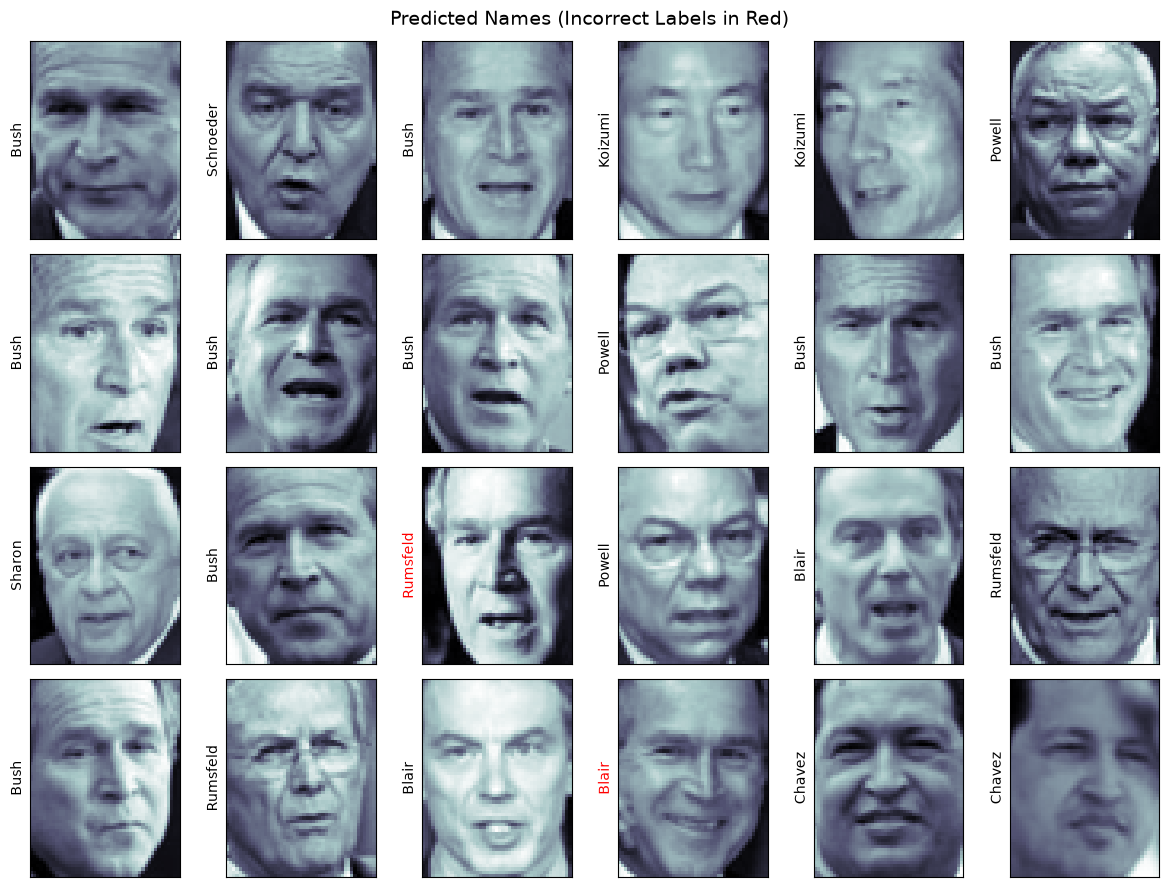

In [6]:
fig, ax = plt.subplots(4, 6, figsize=(12, 9))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names (Incorrect Labels in Red)', size=14)
plt.tight_layout()
plt.show()

## Step 6 - Performance Evaluation (Classification Report & Confusion Matrix)

=== Classification Report ===
                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



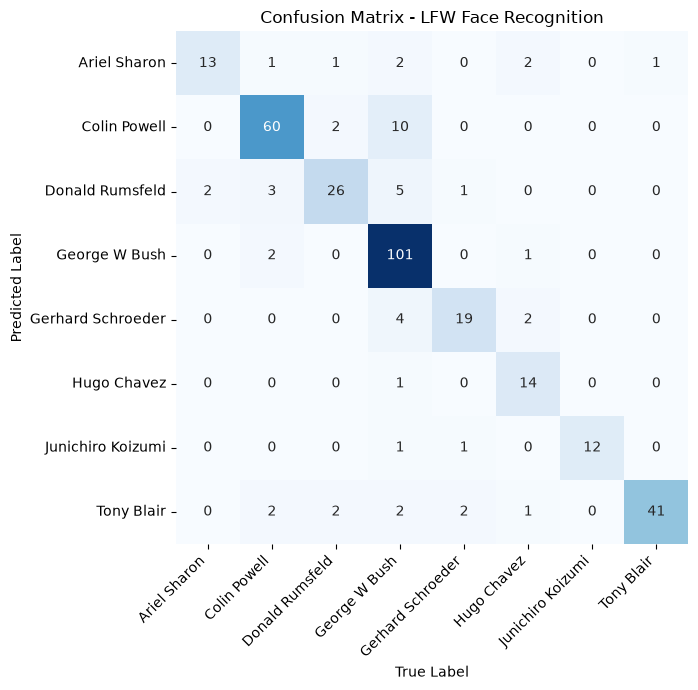

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print('=== Classification Report ===')
print(classification_report(ytest, yfit, target_names=faces.target_names))

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(9, 7))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names,
            cmap='Blues')
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.title('Confusion Matrix - LFW Face Recognition')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()